# EN3160 Assignment 02
## Fitting and Alignment

**Name:** Perera H.A.J.I.  
**Index Number:** 230477X  
**Date:** 19-10-2026

**Assignment Repository:** https://github.com/indeepa-05/EN3160-Image-Processing/tree/main/Assignment2

## Task 1 – Sunflower Blob Detection

### Image loading and preprocessing

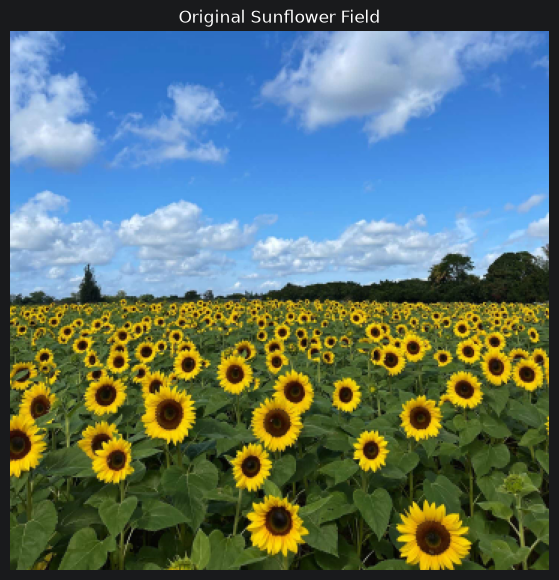

Image dimensions: (360, 360)


In [7]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage

# Read at quarter resolution
image = cv.imread("images/the_berry_farms_sunflower_field.jpeg",cv.IMREAD_REDUCED_COLOR_4)
if image is None:
    raise FileNotFoundError("Image not found")
gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY)
gray = gray.astype(np.float32) / 255.0
plt.figure(figsize=(7, 7))
plt.imshow(cv.cvtColor(image, cv.COLOR_BGR2RGB))
plt.title("Original Sunflower Field")
plt.axis("off")
plt.show()
print("Image dimensions:", gray.shape)

### Scale-normalized Laplacian of Gaussian

In [8]:
sigmas = np.linspace(1.5, 12, 22)
responses = []
for sigma in sigmas:
    log = ndimage.gaussian_laplace(gray, sigma)
    responses.append(sigma**2 * log)
scale_space = np.array(responses)
print("Sigma range:", sigmas[0], "to", sigmas[-1])
print("Number of scales:", len(sigmas))
print("Scale-space shape:", scale_space.shape)

Sigma range: 1.5 to 12.0
Number of scales: 22
Scale-space shape: (22, 360, 360)


In [9]:
# Scale-space extrema detection
neighborhood = ndimage.maximum_filter(scale_space, size=(3, 7, 7))
# Ignore sky and other upper-image structures
start_row = int(gray.shape[0] * 0.42)
# Select a threshold from positive responses in the field
field = scale_space[:, start_row:, :]
positive = field[field > 0]
threshold = np.percentile(positive, 99)
peaks = ((scale_space == neighborhood) &(scale_space > threshold))
peaks[:, :start_row, :] = False
locations = np.argwhere(peaks)
print("Threshold:", round(float(threshold), 4))
print("Candidate blobs:", len(locations))

Threshold: 0.2272
Candidate blobs: 99


### Scale-space extrema detection

In [10]:
# Convert extrema to circle parameters
candidates = []
for k, y, x in locations:
    candidates.append({"x": int(x),"y": int(y),"sigma": float(sigmas[k]),"radius": float(np.sqrt(2) * sigmas[k]),"score": float(scale_space[k, y, x])})
# Strongest responses first
candidates.sort(key=lambda c: c["score"], reverse=True)
circles = []
for c in candidates:
    if all(np.hypot(c["x"] - p["x"], c["y"] - p["y"])> 0.6 * max(c["radius"], p["radius"])for p in circles):
        circles.append(c)
print("Final circles:", len(circles))

Final circles: 99


In [20]:
# Remove false detections using surrounding yellow petals
hsv = cv.cvtColor(image, cv.COLOR_BGR2HSV)
yellow = cv.inRange(hsv, (13, 80, 65), (40, 255, 255)) > 0
filtered = []
height, width = gray.shape
for c in circles:
    x, y, r = c["x"], c["y"], c["radius"]
    # Ignore circles crossing image boundaries
    if x < r or x >= width-r or y < r or y >= height-r:
        continue
    # Examine the region around the detected centre
    R = int(np.ceil(2.2 * r))
    x1, x2 = max(0, x-R), min(width, x+R+1)
    y1, y2 = max(0, y-R), min(height, y+R+1)
    yy, xx = np.ogrid[y1:y2, x1:x2]
    d2 = (xx-x)**2 + (yy-y)**2
    # Ring where surrounding petals are expected
    ring = (d2 >= (1.05*r)**2) & (d2 <= (2.1*r)**2)
    if yellow[y1:y2, x1:x2][ring].mean() > 0.4:
        filtered.append(c)
circles = filtered
print("Filtered circles:", len(circles))

Filtered circles: 84


### Circle visualization

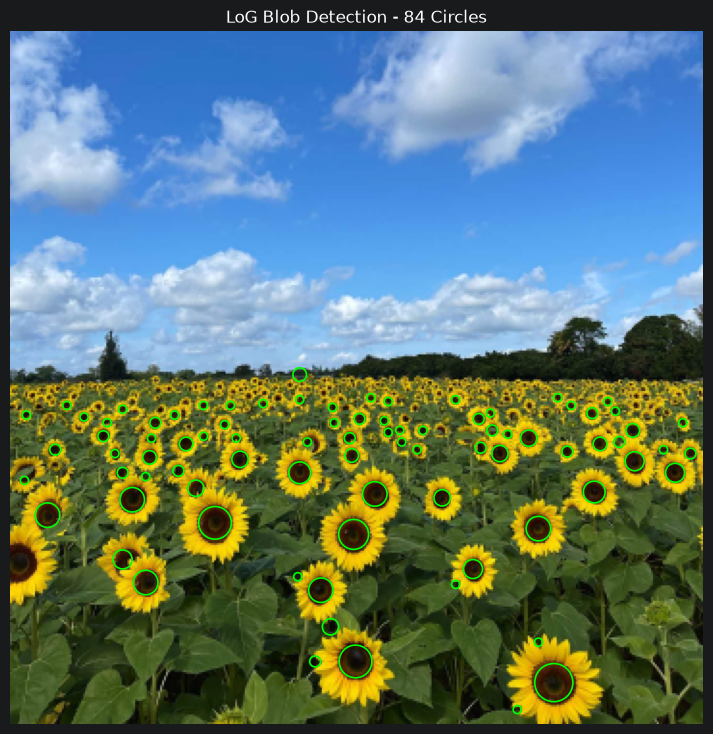

In [21]:
# Visualize detected circles
fig, ax = plt.subplots(figsize=(9, 9))
ax.imshow(cv.cvtColor(image, cv.COLOR_BGR2RGB))
for c in circles:
    ax.add_patch(plt.Circle((c["x"], c["y"]),c["radius"],edgecolor="lime",fill=False,linewidth=1.2))
ax.set_title(f"LoG Blob Detection - {len(circles)} Circles")
ax.axis("off")
plt.show()

### Largest circle parameters and sigma range

Largest Five Detected Circles
 X     Y     Sigma     Radius
282   338   7.00      9.90
106   255   6.00      8.49
179   327   6.00      8.49
178   261   5.50      7.78
189   240   4.50      6.36


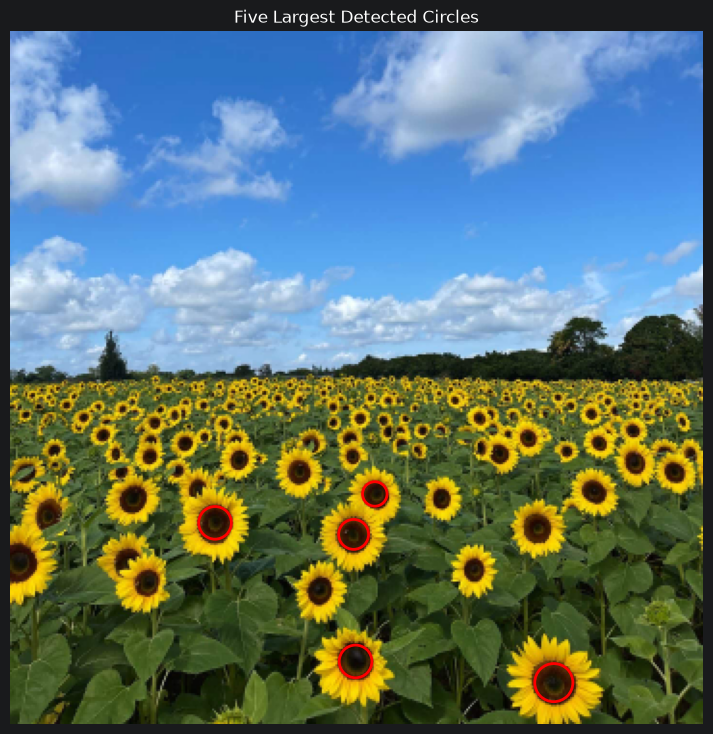

In [22]:
# Report largest five circles
largest = sorted(circles,key=lambda c: c["radius"],reverse=True)[:5]
print("Largest Five Detected Circles")
print(" X     Y     Sigma     Radius")
for c in largest:
    print(
        f"{c['x']:<6}"
        f"{c['y']:<6}"
        f"{c['sigma']:<10.2f}"
        f"{c['radius']:.2f}"
    )
fig, ax = plt.subplots(figsize=(9, 9))
ax.imshow(cv.cvtColor(image, cv.COLOR_BGR2RGB))
for c in largest:
    ax.add_patch(plt.Circle((c["x"], c["y"]),c["radius"],edgecolor="red",fill=False,linewidth=2))
ax.set_title("Five Largest Detected Circles")
ax.axis("off")
plt.show()

### Results and discussion

### Results and Discussion

Sunflower blobs were detected using the scale-normalized Laplacian of Gaussian (LoG) and scale-space extrema detection. The input image was reduced to 360 × 360 pixels, and 22 Gaussian scales ranging from σ = 1.5 to 12.0 were examined. The initial detection identified 99 candidate blobs. A colour based filtering step was then applied to verify the presence of yellow petals surrounding the detected dark centres, reducing the number of detections to 84. The method successfully identified many sunflower centres, particularly those in the foreground. However some smaller or overlapping flowers were missed due to their scale, orientation and proximity to neighbouring flowers. The radius of each detected circle was estimated using \(r=\sqrt{2}\sigma\). The results demonstrate the effectiveness of multiscale LoG detection, while highlighting its limitations in complex scenes containing overlapping objects and background structures.*To be completed after implementing and running this task.*

## Task 2 – RANSAC Line and Circle Fitting

### Generation of noisy data

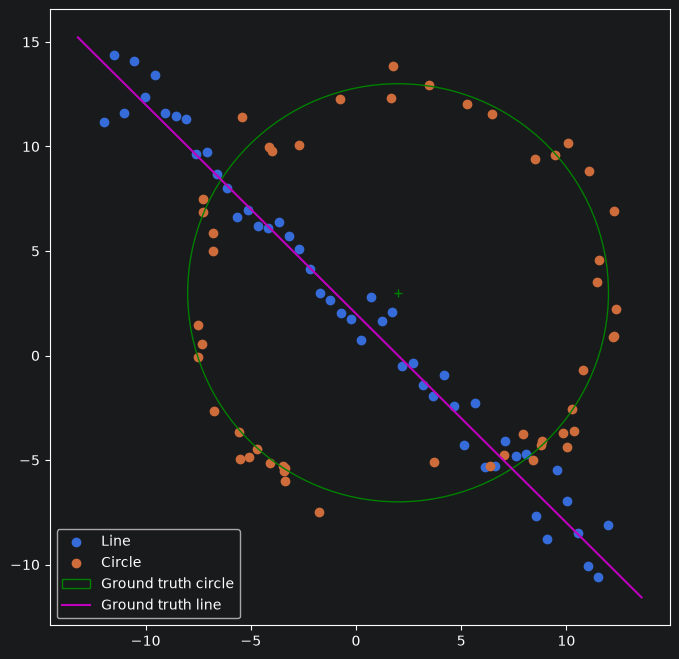

In [23]:
# Generation of a Noisy Point Set Conforming to a Line and a Circle
import numpy as np
from scipy.optimize import minimize
from scipy import linalg
import matplotlib.pyplot as plt
# np.random.seed(0)
N = 100
half_n = N // 2
r = 10
x0_gt, y0_gt = 2, 3  # Center
s = r / 16
t = np.random.uniform(0, 2 * np.pi, half_n)
n = s * np.random.randn(half_n)
x, y = x0_gt + (r + n) * np.cos(t), y0_gt + (r + n) * np.sin(t)
X_circ = np.hstack((x.reshape(half_n, 1), y.reshape(half_n, 1)))
s = 1.
m, b = -1, 2
x = np.linspace(-12, 12, half_n)
y = m * x + b + s * np.random.randn(half_n)
X_line = np.hstack((x.reshape(half_n, 1), y.reshape(half_n, 1)))
X = np.vstack((X_circ, X_line))  # All points
fig, ax = plt.subplots(1, 1, figsize=(8, 8))
ax.scatter(X_line[:, 0], X_line[:, 1], label='Line')
ax.scatter(X_circ[:, 0], X_circ[:, 1], label='Circle')
circle_gt = plt.Circle((x0_gt, y0_gt), r,color='g', fill=False,label='Ground truth circle')
ax.add_patch(circle_gt)
ax.plot((x0_gt), (y0_gt), '+', color='g')
x_min, x_max = ax.get_xlim()
x_ = np.array([x_min, x_max])
y_ = m * x_ + b
plt.plot(x_, y_, color='m', label='Ground truth line')
plt.legend()
plt.show()

### Custom RANSAC line estimation

In [24]:
# Question 2(a) - RANSAC Line Estimation
np.random.seed(42)
threshold = 1.5
min_inliers = 35
iterations = 500
best_count = 0
for _ in range(iterations):
    # Randomly select two points
    indices = np.random.choice(len(X), 2, replace=False)
    p1, p2 = X[indices]
    # Calculate the unit normal vector
    dx, dy = p2 - p1
    length = np.hypot(dx, dy)
    if length == 0:
        continue
    a, b = -dy / length, dx / length
    d = a * p1[0] + b * p1[1]
    # Calculate perpendicular distances
    errors = np.abs(a * X[:, 0] + b * X[:, 1] - d)
    # Determine inliers
    inliers = errors < threshold
    count = np.sum(inliers)
    # Keep the model with the largest consensus
    if count >= min_inliers and count > best_count:
        best_count = count
        line_inliers = inliers.copy()
        line_sample = indices.copy()
        line_normal_sample = np.array([a, b])
        line_d_sample = d
if best_count == 0:
    raise RuntimeError("RANSAC could not find a valid line.")
print("RANSAC inliers:", best_count)
print("Sample-based normal:", line_normal_sample)
print("Sample-based d:", line_d_sample)

RANSAC inliers: 55
Sample-based normal: [0.68891388 0.7248432 ]
Sample-based d: 1.736665535490844


In [25]:
# Refine the line using all RANSAC inliers
points = X[line_inliers]
# Mean of the inlier points
mean = points.mean(axis=0)
# SVD of centered points
U, S, Vt = np.linalg.svd(points - mean)
# The last right-singular vector is the unit normal
a, b = Vt[-1]
# Perpendicular distance from origin
d = a * mean[0] + b * mean[1]
# Ensure d is non-negative
if d < 0:
    a, b, d = -a, -b, -d
line_normal = np.array([a, b])
line_d = d
print("Refined line parameters:")
print(f"a = {a:.4f}")
print(f"b = {b:.4f}")
print(f"d = {d:.4f}")
print(f"Normal magnitude = {np.hypot(a, b):.4f}")

Refined line parameters:
a = 0.7028
b = 0.7114
d = 1.6466
Normal magnitude = 1.0000


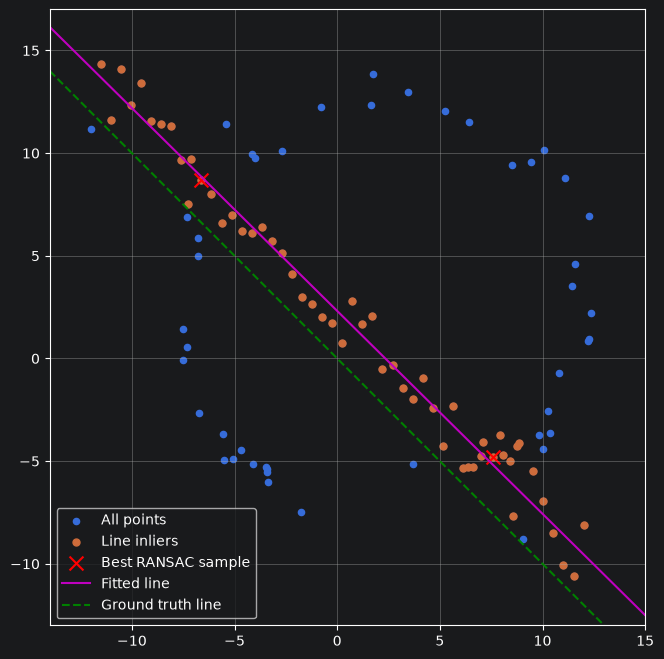

In [29]:
# Visualize RANSAC Line
fig, ax = plt.subplots(figsize=(8, 8))
# All points
ax.scatter(X[:, 0], X[:, 1],s=20, label="All points")
# Line inliers
ax.scatter(X[line_inliers, 0], X[line_inliers, 1],s=25, label="Line inliers")
# Best sample points
ax.scatter(X[line_sample, 0], X[line_sample, 1],color="red", marker="x", s=100,label="Best RANSAC sample")
# Draw the refined line
p = line_d * line_normal
direction = np.array([-b, a])
line_points = np.array([p - 25 * direction,p + 25 * direction])
ax.plot(line_points[:, 0], line_points[:, 1],"m-", label="Fitted line")
# Ground truth line
x_vals = np.array([-14, 14])
ax.plot(x_vals, -x_vals,"g--", label="Ground truth line")
ax.set_xlim(-14, 15)
ax.set_ylim(-13, 17)
ax.set_aspect("equal")
ax.legend()
ax.grid(True)
plt.show()

### Removal of line consensus

In [30]:
# Question 2(b) - Remove line inliers
X_rem = X[~line_inliers]
print("Original points:", len(X))
print("Line inliers removed:", line_inliers.sum())
print("Remaining points:", len(X_rem))

Original points: 100
Line inliers removed: 55
Remaining points: 45


### Custom RANSAC circle estimation

In [31]:
# Question 2(b) - RANSAC Circle Estimation
np.random.seed(42)
threshold_circle = 1.25
min_circle_inliers = 25
iterations = 500
best_count_circle = 0
for _ in range(iterations):
    # Randomly select three points
    indices = np.random.choice(len(X_rem), 3, replace=False)
    p1, p2, p3 = X_rem[indices]
    # Compute circle center from three points
    A = 2 * np.array([p2 - p1, p3 - p1])
    B = np.array([np.dot(p2, p2) - np.dot(p1, p1),np.dot(p3, p3) - np.dot(p1, p1)])
    # Skip collinear or nearly collinear points
    if abs(np.linalg.det(A)) < 1e-6:
        continue
    center = np.linalg.solve(A, B)
    radius = np.linalg.norm(p1 - center)
    # Calculate radial errors
    errors = np.abs(np.linalg.norm(X_rem - center, axis=1) - radius)
    # Find consensus
    inliers = errors < threshold_circle
    count = np.sum(inliers)
    if count >= min_circle_inliers and count > best_count_circle:
        best_count_circle = count
        circle_inliers = inliers.copy()
        circle_sample = indices.copy()
        circle_center_sample = center.copy()
        circle_radius_sample = radius
if best_count_circle == 0:
    raise RuntimeError("RANSAC could not find a valid circle.")
print("Circle inliers:", best_count_circle)
print("Sample-based center:", circle_center_sample)
print("Sample-based radius:", circle_radius_sample)

Circle inliers: 41
Sample-based center: [1.97938471 2.2787942 ]
Sample-based radius: 10.348824261692359


In [32]:
# Refine circle using all detected inliers
from scipy.optimize import minimize
circle_points = X_rem[circle_inliers]
# Sum of squared radial errors
def circle_error(params):
    cx, cy, radius = params
    distances = np.linalg.norm(circle_points - [cx, cy], axis=1)
    return np.sum((distances - radius)**2)
# Initial estimate from RANSAC
initial = [circle_center_sample[0],circle_center_sample[1],circle_radius_sample]
result = minimize(circle_error,initial,bounds=[(None, None), (None, None), (1e-6, None)])
if not result.success:
    raise RuntimeError(result.message)
cx, cy, radius = result.x
circle_center = np.array([cx, cy])
circle_radius = radius
print("Refined circle parameters:")
print(f"Center: ({cx:.4f}, {cy:.4f})")
print(f"Radius: {radius:.4f}")
print(f"Circle inliers: {best_count_circle}")
print("\nGround truth:")
print("Center: (2, 3)")
print("Radius: 10")

Refined circle parameters:
Center: (2.2816, 2.5419)
Radius: 10.0293
Circle inliers: 41

Ground truth:
Center: (2, 3)
Radius: 10


### Joint visualization

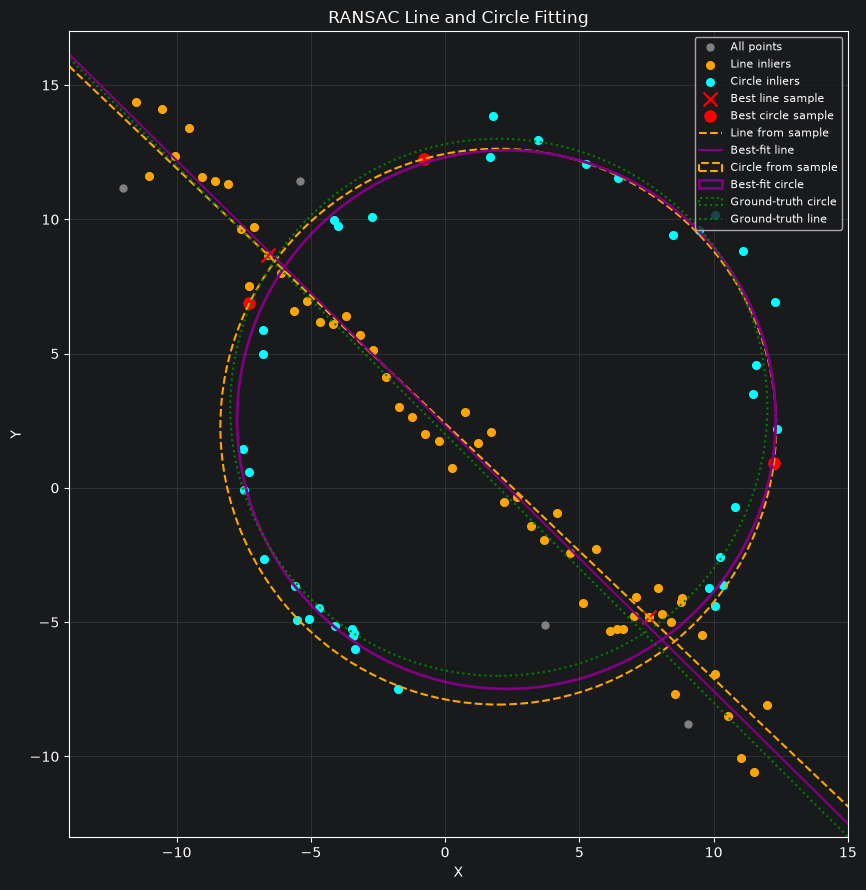

In [33]:
# Question 2(c) - Combined RANSAC Visualization
fig, ax = plt.subplots(figsize=(9, 9))
# 1. Plot all points
ax.scatter(X[:, 0], X[:, 1],color="gray", s=25, label="All points")
# 2. Plot line inliers
ax.scatter(X[line_inliers, 0], X[line_inliers, 1],color="orange", s=30, label="Line inliers")
# 3. Plot circle inliers
ax.scatter(X_rem[circle_inliers, 0],X_rem[circle_inliers, 1],color="cyan", s=30, label="Circle inliers")
# 4. Highlight best RANSAC sample points
ax.scatter(X[line_sample, 0], X[line_sample, 1],color="red", marker="x", s=100,label="Best line sample")
ax.scatter(X_rem[circle_sample, 0],X_rem[circle_sample, 1],color="red", marker="o", s=65,label="Best circle sample")
# 5. Draw sample-based and refined lines
for normal, dist, style, label in [(line_normal_sample, line_d_sample,"orange", "Line from sample"),(line_normal, line_d,"purple", "Best-fit line")]:
    point = dist * normal
    direction = np.array([-normal[1], normal[0]])
    endpoints = np.array([point - 25 * direction,point + 25 * direction])
    ax.plot(endpoints[:, 0], endpoints[:, 1],color=style,linestyle="--" if style == "orange" else "-",linewidth=1.5, label=label)
# 6. Draw sample-based circle
ax.add_patch(plt.Circle(circle_center_sample,circle_radius_sample,fill=False,color="orange",linestyle="--",linewidth=1.5,label="Circle from sample"))
# 7. Draw refined circle
ax.add_patch(plt.Circle(circle_center,circle_radius,fill=False,color="purple",linewidth=2,label="Best-fit circle"))
# 8. Draw ground-truth models
ax.add_patch(plt.Circle((x0_gt, y0_gt), r,fill=False,color="green",linestyle=":",linewidth=1.5,label="Ground-truth circle"))
x_vals = np.array([-14, 15])
ax.plot(x_vals, -x_vals + 2,color="green", linestyle=":",label="Ground-truth line")
# 9. Plot settings
ax.set_xlim(-14, 15)
ax.set_ylim(-13, 17)
ax.set_aspect("equal")
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_title("RANSAC Line and Circle Fitting")
ax.legend(fontsize=8, loc="upper right")
ax.grid(True, alpha=0.2)
plt.tight_layout()
plt.show()

In [34]:
# Compare fitted parameters with ground truth
true_center = np.array([x0_gt, y0_gt])
true_normal = np.array([1, 1]) / np.sqrt(2)
true_d = 2 / np.sqrt(2)
# Line errors
angle_error = np.degrees(np.arccos(np.clip(abs(np.dot(line_normal, true_normal)), 0, 1)))
line_distance_error = abs(line_d - true_d)
# Circle errors
center_error = np.linalg.norm(circle_center - true_center)
radius_error = abs(circle_radius - r)
print(f"Line angle error: {angle_error:.3f} degrees")
print(f"Line distance error: {line_distance_error:.3f}")
print(f"Circle center error: {center_error:.3f}")
print(f"Circle radius error: {radius_error:.3f}")

Line angle error: 0.346 degrees
Line distance error: 0.232
Circle center error: 0.538
Circle radius error: 0.029


### Effect of fitting the circle first
A circle has three parameters and requires three sample points while a line has two parameters and requires only two sample points. If we fit the circle first, RANSAC might choose three nearly collinear points from the line. These points can define an extremely large circle whose boundary resembles a straight line locally. Consequently RANSAC could incorrectly identify line points as circle inliers. Even if the correct circle is detected points near the intersections of the line and circle may be assigned to the wrong model. This could reduce the accuracy of the subsequent line fitting. Therefore fitting the line first is generally more reliable for this particular dataset.

### Question 2 – Results and Discussion

**Line Estimation:** RANSAC was implemented using randomly selected pairs of points a perpendicular distance threshold of 1.5, a minimum consensus of 35 points and 500 iterations. The best line model identified 55 inliers. Total Least Squares refinement produced the parameters \(a=0.7028\), \(b=0.7114\), and \(d=1.6466\) with a unit normal vector. The angular error relative to the ground truth line was only 0.346°.

**Circle Estimation:** After removing the line inliers 45 points remained. Circle RANSAC was applied using three point samples, a radial error threshold of 1.25 and 500 iterations. The algorithm identified 41 circle inliers. Nonlinear least squares refinement produced a centre of (2.2816, 2.5419) and radius of 10.0293. The centre error was 0.538 while the radius error was only 0.029.

**Effect of Fitting the Circle First:** Fitting the circle before the line can be less reliable because three nearly collinear points may produce a circle with an excessively large radius approximating a straight line. Furthermore points near the intersection of the two models can be incorrectly assigned. Fitting the simpler line model first reduces this ambiguity.

**Conclusion:** Both fitted models closely approximate the ground truth. RANSAC successfully separates the noisy point sets while refinement using all detected inliers improves parameter estimation compared with using the minimal random samples alone.

## Task 3 – Homography and Image Compositing

### Image-pair selection and Correspondence point selection

In [35]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
# Load images
target = cv.imread("images/wadham.jpg")
overlay = cv.imread("images/flag.png")
if target is None or overlay is None:
    raise FileNotFoundError("Check image paths")
# Store selected points
points = []
preview = target.copy()
def select_point(event, x, y, flags, param):
    if event == cv.EVENT_LBUTTONDOWN and len(points) < 4:
        points.append([x, y])
        cv.circle(preview, (x, y), 5, (0, 0, 255), -1)
        cv.putText(preview, str(len(points)), (x+8, y-8),cv.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 255), 2)
print("Click corners in this order:")
print("Top-left -> Top-right -> Bottom-right -> Bottom-left")
print("Press ESC to cancel")
cv.namedWindow("Select 4 Corners", cv.WINDOW_AUTOSIZE)
cv.setMouseCallback("Select 4 Corners", select_point)
while len(points) < 4:
    cv.imshow("Select 4 Corners", preview)
    if cv.waitKey(20) & 0xFF == 27:
        break
cv.destroyAllWindows()
if len(points) != 4:
    raise RuntimeError("Four points were not selected")
print("Selected points:", points)

Click corners in this order:
Top-left -> Top-right -> Bottom-right -> Bottom-left
Press ESC to cancel
Selected points: [[147, 204], [515, 289], [520, 464], [134, 447]]


### Homography estimation

In [36]:
h, w = overlay.shape[:2]
H_target, W_target = target.shape[:2]
# Four corners of the overlay image
src_pts = np.float32([[0, 0],[w-1, 0],[w-1, h-1],[0, h-1]])
# Four selected target points
dst_pts = np.float32(points)
# Calculate homography
H, _ = cv.findHomography(src_pts, dst_pts)
if H is None:
    raise RuntimeError("Homography estimation failed")
# Warp overlay onto target
warped = cv.warpPerspective(overlay, H, (W_target, H_target))
# Mask for the selected region
mask = np.zeros((H_target, W_target), dtype=np.uint8)
cv.fillConvexPoly(mask, dst_pts.astype(np.int32), 255)
# Blend original image and warped overlay
alpha = 0.75
blended = cv.addWeighted(target, 1-alpha, warped, alpha, 0)
result = target.copy()
result[mask > 0] = blended[mask > 0]
print("Homography matrix:")
print(H)

Homography matrix:
[[ 2.97395670e-01 -2.07840361e-02  1.47000000e+02]
 [ 1.03569276e-01  2.29276803e-01  2.04000000e+02]
 [ 2.05105096e-04 -5.39421553e-05  1.00000000e+00]]


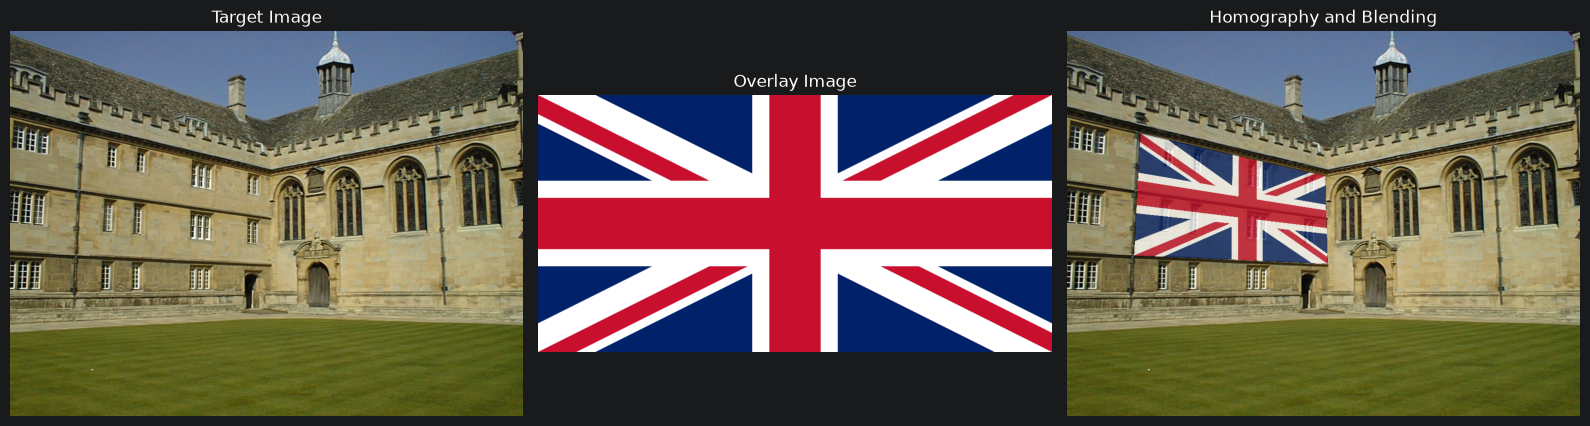

In [37]:
# Display original, overlay and final result
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
axes[0].imshow(cv.cvtColor(target, cv.COLOR_BGR2RGB))
axes[0].set_title("Target Image")
axes[1].imshow(cv.cvtColor(overlay, cv.COLOR_BGR2RGB))
axes[1].set_title("Overlay Image")
axes[2].imshow(cv.cvtColor(result, cv.COLOR_BGR2RGB))
axes[2].set_title("Homography and Blending")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

### Example 2 – Perspective Warping with custom images

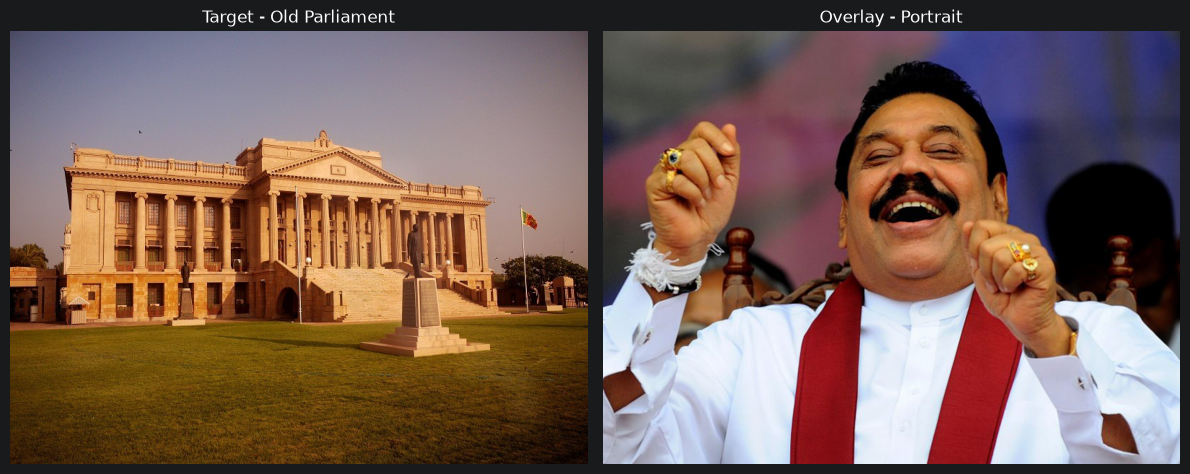

In [38]:
# Question 3 - Example 2: Image Loading
parliament = cv.imread("images/old_parliament.jpg")
portrait = cv.imread("images/Mahinda.jpg")
if parliament is None or portrait is None:
    raise FileNotFoundError("Check image paths")
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(cv.cvtColor(parliament, cv.COLOR_BGR2RGB))
axes[0].set_title("Target - Old Parliament")
axes[1].imshow(cv.cvtColor(portrait, cv.COLOR_BGR2RGB))
axes[1].set_title("Overlay - Portrait")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

In [39]:
# Select four points on the Parliament building
parliament_points = []
parliament_preview = parliament.copy()
def parliament_click(event, x, y, flags, param):
    if event == cv.EVENT_LBUTTONDOWN and len(parliament_points) < 4:
        parliament_points.append([x, y])
        cv.circle(parliament_preview, (x, y),5, (0, 0, 255), -1)
        cv.putText(parliament_preview,str(len(parliament_points)),(x+8, y-8),cv.FONT_HERSHEY_SIMPLEX,0.7, (0, 255, 255), 2)
print("Click: Top-left, Top-right, Bottom-right, Bottom-left")
window = "Parliament - Select 4 Corners"
cv.namedWindow(window, cv.WINDOW_NORMAL)
cv.setMouseCallback(window, parliament_click)
while len(parliament_points) < 4:
    cv.imshow(window, parliament_preview)
    if cv.waitKey(20) & 0xFF == 27:
        break
cv.destroyAllWindows()
if len(parliament_points) != 4:
    raise RuntimeError("Four points required")
print("Selected points:", parliament_points)

Click: Top-left, Top-right, Bottom-right, Bottom-left
Selected points: [[87, 192], [325, 210], [329, 334], [84, 333]]


In [40]:
# Homography and Perspective Warping - Example 2
h, w = portrait.shape[:2]
H_target, W_target = parliament.shape[:2]
# Source image corners
src = np.float32([[0, 0],[w-1, 0],[w-1, h-1],[0, h-1]])
# Selected destination corners
dst = np.float32(parliament_points)
# Compute homography
H_parliament, _ = cv.findHomography(src, dst)
if H_parliament is None:
    raise RuntimeError("Homography calculation failed")
# Warp portrait
warped_portrait = cv.warpPerspective(portrait, H_parliament, (W_target, H_target))
# Create mask
mask = np.zeros((H_target, W_target), dtype=np.uint8)
cv.fillConvexPoly(mask, dst.astype(np.int32), 255)
# Alpha blending
alpha = 0.75
blended = cv.addWeighted(parliament, 1-alpha,warped_portrait, alpha, 0)
parliament_result = parliament.copy()
parliament_result[mask > 0] = blended[mask > 0]
print("Homography matrix:")
print(H_parliament)

Homography matrix:
[[ 1.38073871e-01 -3.64062491e-03  8.70000000e+01]
 [ 2.28834916e-02  8.51719899e-02  1.92000000e+02]
 [ 6.70958830e-05 -2.00741370e-05  1.00000000e+00]]


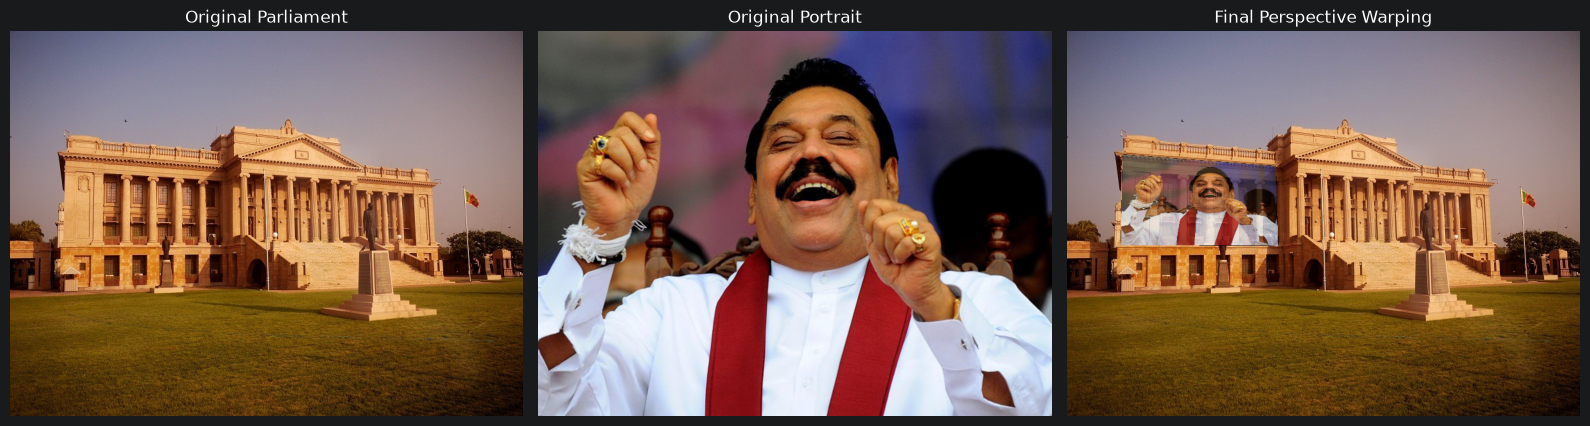

In [41]:
# Visualize Example 2 Results
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
images = [parliament,portrait,parliament_result]
titles = ["Original Parliament","Original Portrait","Final Perspective Warping"]
for ax, img, title in zip(axes, images, titles):
    ax.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

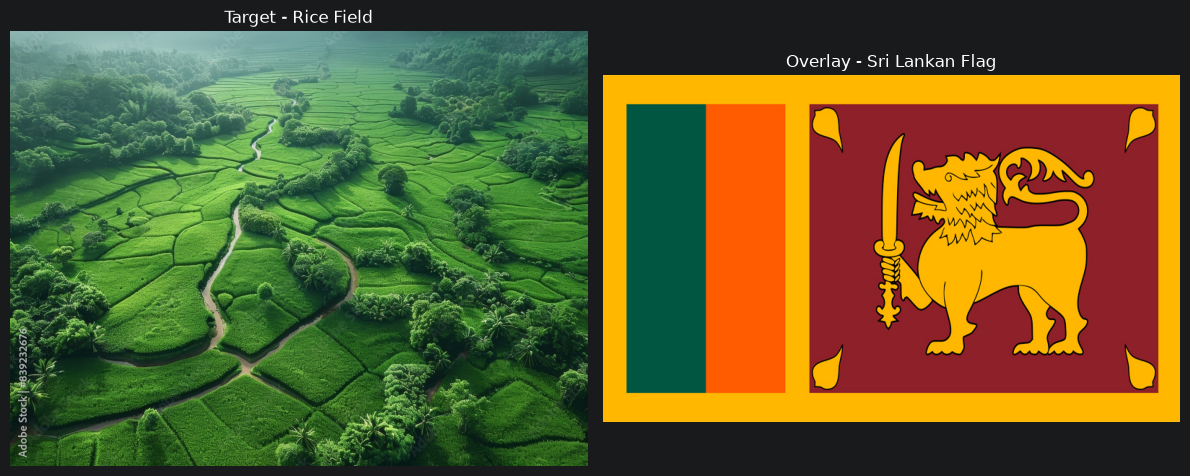

In [43]:
# Question 3 - Example 3: Image Loading
rice_field = cv.imread("images/Paddy_field.jpg")
sl_flag = cv.imread("images/SL_Flag.jpg")
if rice_field is None or sl_flag is None:
    raise FileNotFoundError("Check image paths")
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(cv.cvtColor(rice_field, cv.COLOR_BGR2RGB))
axes[0].set_title("Target - Rice Field")
axes[1].imshow(cv.cvtColor(sl_flag, cv.COLOR_BGR2RGB))
axes[1].set_title("Overlay - Sri Lankan Flag")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

In [44]:
# Select four points on the rice field image
rice_points = []
rice_preview = rice_field.copy()
def rice_click(event, x, y, flags, param):
    if event == cv.EVENT_LBUTTONDOWN and len(rice_points) < 4:
        rice_points.append([x, y])
        cv.circle(rice_preview, (x, y), 5, (0, 0, 255), -1)
        cv.putText(rice_preview,str(len(rice_points)),(x + 8, y - 8),cv.FONT_HERSHEY_SIMPLEX,0.7,(0, 255, 255),2)
print("Click in this order:")
print("Top-left, Top-right, Bottom-right, Bottom-left")
window_name = "Rice Field - Select 4 Corners"
cv.namedWindow(window_name, cv.WINDOW_NORMAL)
cv.setMouseCallback(window_name, rice_click)
while len(rice_points) < 4:
    cv.imshow(window_name, rice_preview)
    if cv.waitKey(20) & 0xFF == 27:
        break
cv.destroyAllWindows()
if len(rice_points) != 4:
    raise RuntimeError("Four points were not selected")
print("Selected points:", rice_points)

Click in this order:
Top-left, Top-right, Bottom-right, Bottom-left
Selected points: [[328, 634], [524, 505], [613, 584], [428, 719]]


In [45]:
# Homography and Perspective Warping - Example 3
h, w = sl_flag.shape[:2]
H_target, W_target = rice_field.shape[:2]
src_pts = np.float32([[0, 0],[w - 1, 0],[w - 1, h - 1],[0, h - 1]])
dst_pts = np.float32(rice_points)
H_rice, _ = cv.findHomography(src_pts, dst_pts)
if H_rice is None:
    raise RuntimeError("Homography calculation failed")
warped_flag = cv.warpPerspective(sl_flag, H_rice, (W_target, H_target))
mask = np.zeros((H_target, W_target), dtype=np.uint8)
cv.fillConvexPoly(mask, dst_pts.astype(np.int32), 255)
alpha = 0.75
blended_rice = cv.addWeighted(rice_field, 1 - alpha, warped_flag, alpha, 0)
rice_result = rice_field.copy()
rice_result[mask > 0] = blended_rice[mask > 0]
print("Homography matrix:")
print(H_rice)

Homography matrix:
[[ 3.09213968e-01  2.20008671e-01  3.28000000e+02]
 [-9.98617310e-02  1.96335854e-01  6.34000000e+02]
 [ 1.21960562e-04  2.62626247e-05  1.00000000e+00]]


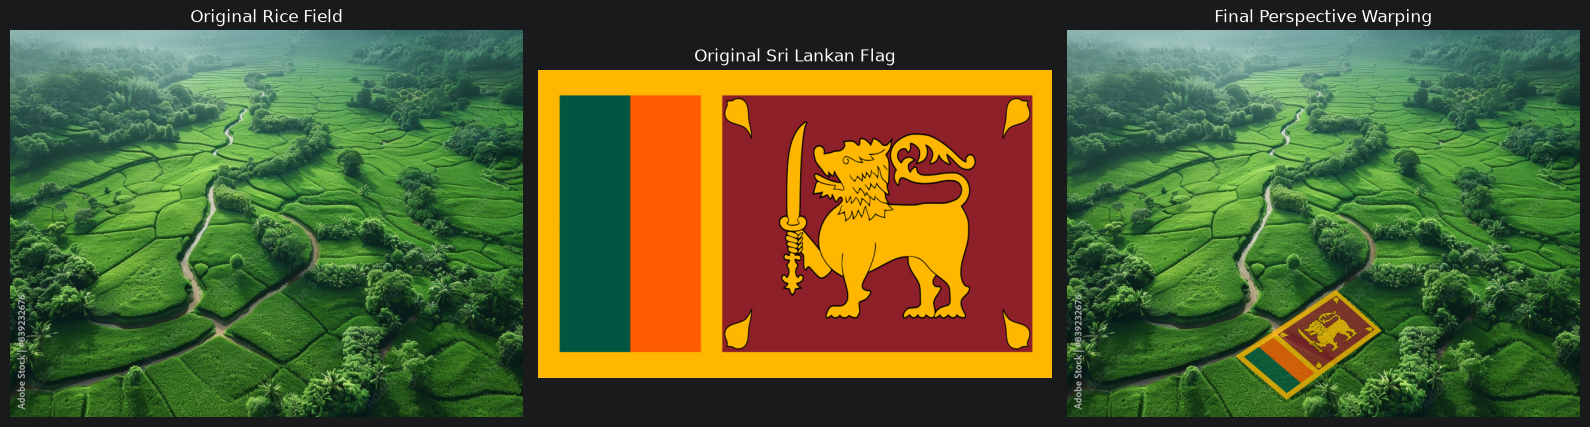

In [46]:
# Visualize Example 3 Result
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
images = [rice_field, sl_flag, rice_result]
titles = ["Original Rice Field","Original Sri Lankan Flag","Final Perspective Warping"]
for ax, img, title in zip(axes, images, titles):
    ax.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

### Results and discussion

### Question 3 – Results and Discussion

Homography based perspective warping was implemented using four corresponding points between an overlay image and a selected region of a target image. The homography matrix was calculated using `cv.findHomography()` and `cv.warpPerspective()` was used to transform the overlay. Alpha blending with a factor of 0.75 was applied within the selected region to combine the transformed image with the background.

Three examples were implemented. The British flag was projected onto the Wadham College building as an initial demonstration. Two additional image pairs were used. A portrait projected onto the Old Parliament Building and the Sri Lankan flag projected onto a paddy field region.

All three transformations successfully mapped the overlay images onto their selected quadrilateral regions. However the Parliament example demonstrates a limitation of homography when the selected region includes architectural features at different depths. Similarly, the paddy field is not a perfectly planar surface affecting the physical realism of the result.

Overall, the experiments demonstrate that homography can successfully model perspective transformations between planar image regions, while the quality of the final composition depends on the selected correspondence points, surface geometry and blending parameters.

## Task 4 – PCB Image Alignment

### SIFT feature detection

### Brute-force descriptor matching

### RANSAC homography estimation

### Image alignment

### Difference-image computation

### Comparison across all PCB images

### Interpretation of high differences at raised PCB components

*To be completed after implementing and running this task.*